# Figure 2

In this notebook, we'll generate figure panels for use in Figure 4, the overview of Lenalidomide treatment results.

For the UMAP plots, see the notebook for Figure 1. In this notebook, we'll generate the differential result barplots, Hallmark Pathway heatmaps, and motif enrichment volcano plots.

## Load packages

hise: The Human Immune System Explorer R SDK package  
purrr: Functional programming tools  
dplyr: Dataframe handling functions  
ggplot2: plotting functions  
ggrepel: text plotting with repulsion  
cowplot: multi-panel plot assembly

In [1]:
quiet_library <- function(...) { suppressPackageStartupMessages(library(...)) }
quiet_library(hise)
quiet_library(purrr)
quiet_library(dplyr)
quiet_library(ggplot2)
quiet_library(ggrepel)
quiet_library(cowplot)

Warning message:
“package ‘purrr’ was built under R version 4.4.3”
Warning message:
“package ‘dplyr’ was built under R version 4.4.3”
Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘ggrepel’ was built under R version 4.4.3”
Warning message:
“package ‘cowplot’ was built under R version 4.4.3”


In [2]:
out_dir <- "output/figure_4"
if(!dir.exists(out_dir)) { dir.create(out_dir, recursive = TRUE) }

In [3]:
out_files <- c()

## Retrieve files

Now, we'll use the HISE SDK package to retrieve the analysis results for DEG, Hallmark Pathway enrichment, and motif enrichment.

DEG: Differentially expressed genes

In [4]:
deg_uuid <- list("fc83b89f-fd26-43b8-ac91-29c539703a45")

In [5]:
deg_uuid <- list("8a6de5d9-4939-45cc-b77e-f2d8237a68b7")

In [6]:
deg_file <- cacheFiles(deg_uuid)

[2026-10-06 12:57:52] INFO  Calling cacheFiles
[1] "downloading fileID 8a6de5d9-4939-45cc-b77e-f2d8237a68b7"
[2026-10-06 12:57:59] INFO  Finished cacheFiles successfully (time_elapsed=3.442s)


In [7]:
deg_file

[1] "/home/workspace/input/1918706177/cohorts/8a6de5d9-4939-45cc-b77e-f2d8237a68b7/shapely_ladybug/all_mast_deg_2024-04-29.csv"

DEP: Differentially expressed proteins (ADT)

In [8]:
dep_uuid <- list("4cbaa9ab-f8ef-495d-ac5e-1f1d99d33e33")

In [9]:
dep_file <- cacheFiles(dep_uuid)

[2026-10-06 12:57:59] INFO  Calling cacheFiles
[1] "downloading fileID 4cbaa9ab-f8ef-495d-ac5e-1f1d99d33e33"
[2026-10-06 12:58:03] INFO  Finished cacheFiles successfully (time_elapsed=1.941s)


DAP: Differentially accessible peaks (ATAC)

In [10]:
dap_uuid <- list("a8973524-cc71-40d5-8edf-3d6a9e0a77d4")

In [11]:
dap_file <- cacheFiles(dap_uuid)

[2026-10-06 12:58:03] INFO  Calling cacheFiles
[1] "downloading fileID a8973524-cc71-40d5-8edf-3d6a9e0a77d4"
[2026-10-06 12:58:08] INFO  Finished cacheFiles successfully (time_elapsed=1.956s)


In [12]:
hallmark_uuid <- list("4f05f2a0-59d2-4d04-b948-70d541613e71")

In [13]:
hallmark_file <- cacheFiles(hallmark_uuid)

[2026-10-06 12:58:08] INFO  Calling cacheFiles
[1] "downloading fileID 4f05f2a0-59d2-4d04-b948-70d541613e71"
[2026-10-06 12:58:12] INFO  Finished cacheFiles successfully (time_elapsed=1.723s)


In [14]:
dem_uuid <- list("42adb44f-71d2-4d8b-a80c-73b0833d6a1d")

In [15]:
dem_file <- cacheFiles(dem_uuid)

[2026-10-06 12:58:12] INFO  Calling cacheFiles
[1] "downloading fileID 42adb44f-71d2-4d8b-a80c-73b0833d6a1d"
[2026-10-06 12:58:17] INFO  Finished cacheFiles successfully (time_elapsed=1.926s)


## Differential expression barplots

### DEG Barplots

In [16]:
fdr_cutoff <- 0.05

In [17]:
type_colors <- read.csv("../common/color_sets/aifi_cell_type_colors.csv")

In [18]:
all_deg <- read.csv(deg_file)

In [19]:
all_deg <- all_deg %>%
  mutate(
      direction_sign = ifelse(
          is.na(logFC),
          sign(coef_D),
          sign(logFC)
      ),
      direction = ifelse(
          direction_sign == 1,
          "up", "dn"
      )
  )

In [20]:
all_deg <- all_deg %>%
  filter(fg == "lenalidomide")

In [21]:
deg_summary <- all_deg %>%
  group_by(fg, timepoint, aifi_cell_type, n_sample) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [22]:
plot_data <- deg_summary %>%
  rename(aifi_cell_type = aifi_cell_type) %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [23]:
plot_data %>%
  filter(fg == "lenalidomide",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sample,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<int>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
lenalidomide,4,t_cd4_naive,1352,292,210,82,CD4 Naive,#93A7D1,1,7,lenalidomide_4,572
lenalidomide,24,t_cd4_naive,1352,1033,572,461,CD4 Naive,#93A7D1,1,7,lenalidomide_24,572
lenalidomide,72,t_cd4_naive,1352,454,265,189,CD4 Naive,#93A7D1,1,7,lenalidomide_72,572


In [24]:
deg_plot_data_file <- file.path(out_dir, paste0("lenalidomide_deg_summary_data_", Sys.Date(), ".csv"))
write.csv(
    plot_data,
    deg_plot_data_file,
    quote = FALSE,
    row.names = FALSE
)
out_files <- c(out_files, deg_plot_data_file)

In [25]:
treat_times <- paste0("lenalidomide_", c(4, 24, 72))

In [26]:
options(repr.plot.width = 12, repr.plot.height = 4)
treat_plots <- map(
    treat_times,
    function(tt) {
                
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        
        timepoint <- pd$timepoint[1]
        pd_max <- max(max(pd$n_dn), max(pd$n_up))
        if(pd_max < 100) {
            pd_max <- 100
        }
        
        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sample, n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.2, y = cell_type_ypos,
                        label = n_sample),
                    hjust = 1)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DEGs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

In [27]:
treat_times

[1] "lenalidomide_4"  "lenalidomide_24" "lenalidomide_72"

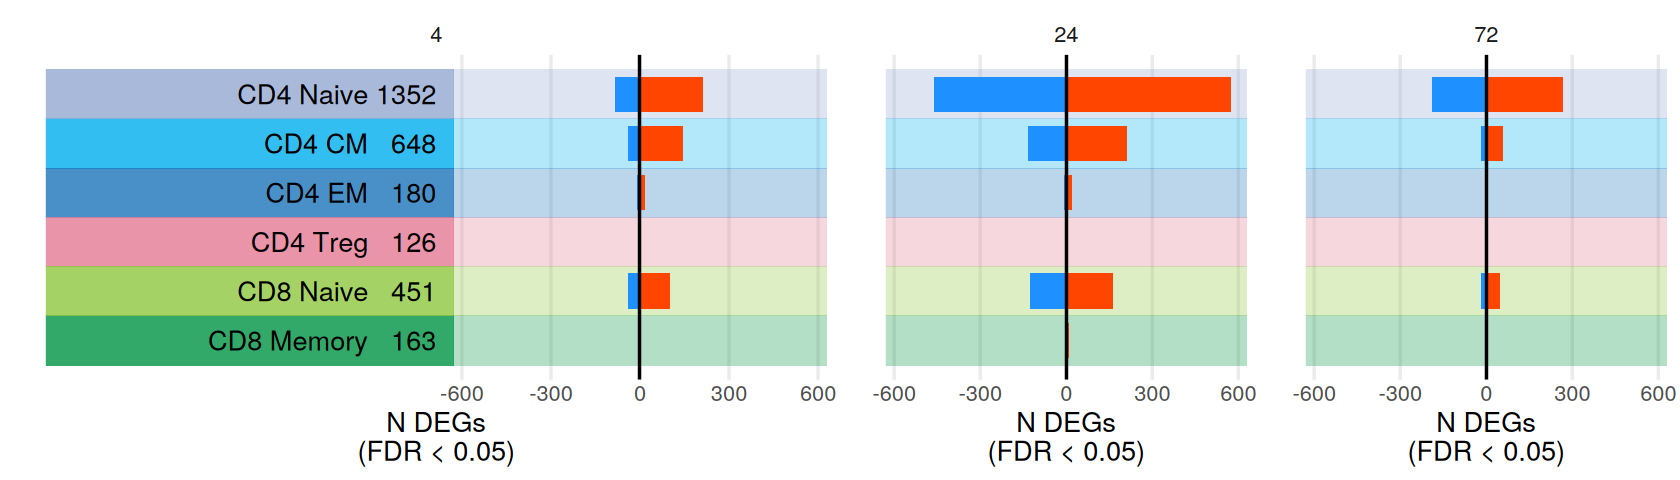

In [28]:
options(repr.plot.width = 14, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 3,
    rel_widths = c(2,1,1)
)
all_plots

In [29]:
deg_plot_file <- file.path(
    out_dir,
    paste0("lenalidomide_deg_barplot_",Sys.Date(),".pdf")
)
ggsave(deg_plot_file,
       all_plots,
       width = 14, height = 4)
out_files <- c(out_files, deg_plot_file)

### DAP Barplots

In [30]:
fdr_cutoff <- 0.05

In [31]:
all_dap <- read.csv(dap_file)

In [32]:
head(all_dap)

,aifi_cell_type,fg,bg,seqnames,start,end,logFC,adjP,MeanDiff,idx
,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>
1,t_cd4_cm,bortezomib_4,dmso_4,chr1,817097,817597,0.76247158,0.9617006,0.016549055,1
2,t_cd4_cm,bortezomib_4,dmso_4,chr1,827316,827816,-0.01214597,0.9617006,-0.002062272,2
3,t_cd4_cm,bortezomib_4,dmso_4,chr1,844402,844902,-0.72051897,0.9617006,-0.017751078,3
4,t_cd4_cm,bortezomib_4,dmso_4,chr1,903980,904480,-1.17605733,0.9617006,-0.016888331,6
5,t_cd4_cm,bortezomib_4,dmso_4,chr1,904495,904995,-0.21563641,0.9617006,-0.040113108,7
6,t_cd4_cm,bortezomib_4,dmso_4,chr1,942207,942707,-0.89654326,0.9617006,-0.042661663,16


In [33]:
all_dap <- all_dap %>%
  mutate(timepoint = sub(".+_","",fg),
         fg = sub("_.+","",fg),
         bg = sub("_.+","",bg)) %>%
  filter(fg == "lenalidomide") %>%
  mutate(direction = ifelse(logFC > 0, "up", "dn"))

In [34]:
head(all_dap)

,aifi_cell_type,fg,bg,seqnames,start,end,logFC,adjP,MeanDiff,idx,timepoint,direction
,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<chr>,<chr>
1,t_cd4_cm,lenalidomide,dmso,chr1,236604238,236604738,2.093293,2.882234e-15,0.4113537,7199,4,up
2,t_cd4_cm,lenalidomide,dmso,chr15,67150342,67150842,2.729955,1.124049e-13,0.3793228,1193,4,up
3,t_cd4_cm,lenalidomide,dmso,chr1,234724186,234724686,1.546861,1.971491e-13,0.4868936,7081,4,up
4,t_cd4_cm,lenalidomide,dmso,chr7,6374176,6374676,1.321119,1.971491e-13,0.5133141,402,4,up
5,t_cd4_cm,lenalidomide,dmso,chr11,68471843,68472343,1.945509,2.084277e-12,0.4141671,2388,4,up
6,t_cd4_cm,lenalidomide,dmso,chr8,100502290,100502790,2.426262,5.581893e-12,0.3728084,1573,4,up


In [35]:
table(all_dap$aifi_cell_type)


    t_cd4_cm     t_cd4_em  t_cd4_naive   t_cd4_treg t_cd8_memory  t_cd8_naive 
      217715       212987       202190       175052       203978       217988 

In [36]:
dap_summary <- all_dap %>%
  group_by(fg, timepoint, aifi_cell_type) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [37]:
head(dap_summary)

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn
<chr>,<chr>,<chr>,<int>,<int>,<int>
lenalidomide,24,t_cd4_cm,2771,2155,616
lenalidomide,24,t_cd4_em,3197,2532,665
lenalidomide,24,t_cd4_naive,2325,1787,538
lenalidomide,24,t_cd4_treg,41,38,3
lenalidomide,24,t_cd8_memory,2526,2064,462
lenalidomide,24,t_cd8_naive,3252,2492,760


In [38]:
plot_data <- dap_summary %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [39]:
plot_data %>%
  filter(fg == "lenalidomide",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
lenalidomide,24,t_cd4_naive,2325,1787,538,CD4 Naive,#93A7D1,1,7,lenalidomide_24,2532
lenalidomide,4,t_cd4_naive,511,482,29,CD4 Naive,#93A7D1,1,7,lenalidomide_4,2532
lenalidomide,72,t_cd4_naive,354,312,42,CD4 Naive,#93A7D1,1,7,lenalidomide_72,2532


In [40]:
dap_plot_data_file <- file.path(out_dir, paste0("lenalidomide_dap_summary_data_", Sys.Date(), ".csv"))
write.csv(
    plot_data,
    dap_plot_data_file,
    quote = FALSE,
    row.names = FALSE
)
out_files <- c(out_files, dap_plot_data_file)

In [41]:
treat_times <- paste0("lenalidomide_", c(4, 24, 72))

In [42]:
options(repr.plot.width = 12, repr.plot.height = 4)
treat_plots <- map(
    treat_times,
    function(tt) {
        
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        x_max <- max(x_max, x_breaks[length(x_breaks)])
        x_min <- min(x_min, x_breaks[1])
        
        timepoint <- pd$timepoint[1]

        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DAPs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

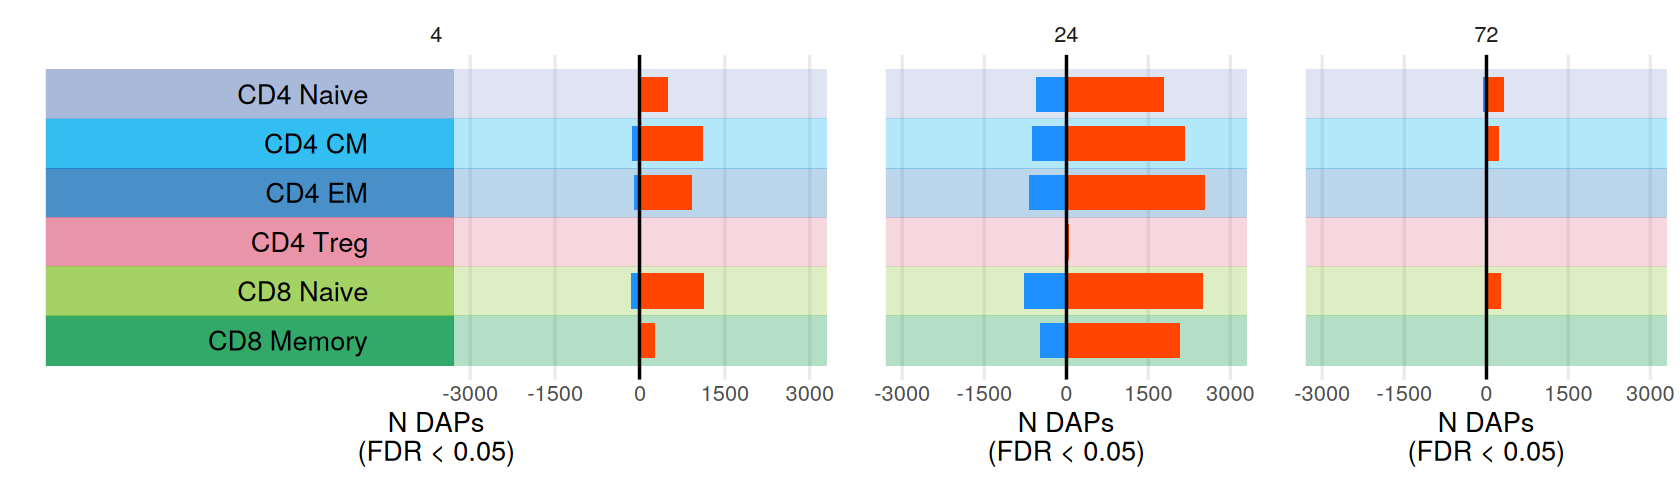

In [43]:
options(repr.plot.width = 14, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 3,
    rel_widths = c(2,1,1)
)
all_plots

In [44]:
dap_plot_file <- file.path(
    out_dir,
    paste0("lenalidomide_dap_barplot_",Sys.Date(),".pdf")
)
ggsave(dap_plot_file,
       all_plots,
       width = 14, height = 4)
out_files <- c(out_files, dap_plot_file)

### DDE Barplots
Differentially detected epitopes, aka Differentially expressed proteins (DEP)

In [45]:
fdr_cutoff <- 0.05

In [46]:
all_dep <- read.csv(dep_file)

In [47]:
all_dep <- all_dep %>%
  filter(fg == "lenalidomide") %>%
  mutate(direction = ifelse(logFC > 0, "up", "dn"))

In [48]:
dep_epitope_summary <- all_dep %>%
  filter(adjP < fdr_cutoff) %>%
  group_by(fg, feature, direction) %>%
  summarise(n_types_up = n(), .groups = "keep")

In [49]:
dep_summary <- all_dep %>%
  group_by(fg, timepoint, aifi_cell_type) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [50]:
plot_data <- dep_summary %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [51]:
plot_data %>%
  filter(fg == "lenalidomide",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<int>,<chr>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
lenalidomide,4,t_cd4_naive,2,0,2,CD4 Naive,#93A7D1,1,7,lenalidomide_4,7
lenalidomide,24,t_cd4_naive,4,2,2,CD4 Naive,#93A7D1,1,7,lenalidomide_24,7
lenalidomide,72,t_cd4_naive,10,3,7,CD4 Naive,#93A7D1,1,7,lenalidomide_72,7


In [52]:
dde_plot_data_file <- file.path(out_dir, paste0("lenalidomide_dde_summary_data_", Sys.Date(), ".csv"))
write.csv(
    plot_data,
    dde_plot_data_file,
    quote = FALSE,
    row.names = FALSE
)
out_files <- c(out_files, dde_plot_data_file)

In [53]:
treat_times <- paste0("lenalidomide_", c(4, 24, 72))

In [54]:
options(repr.plot.width = 12, repr.plot.height = 4)
treat_plots <- map(
    treat_times,
    function(tt) {
        
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        
        timepoint <- pd$timepoint[1]
        
        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DDEs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

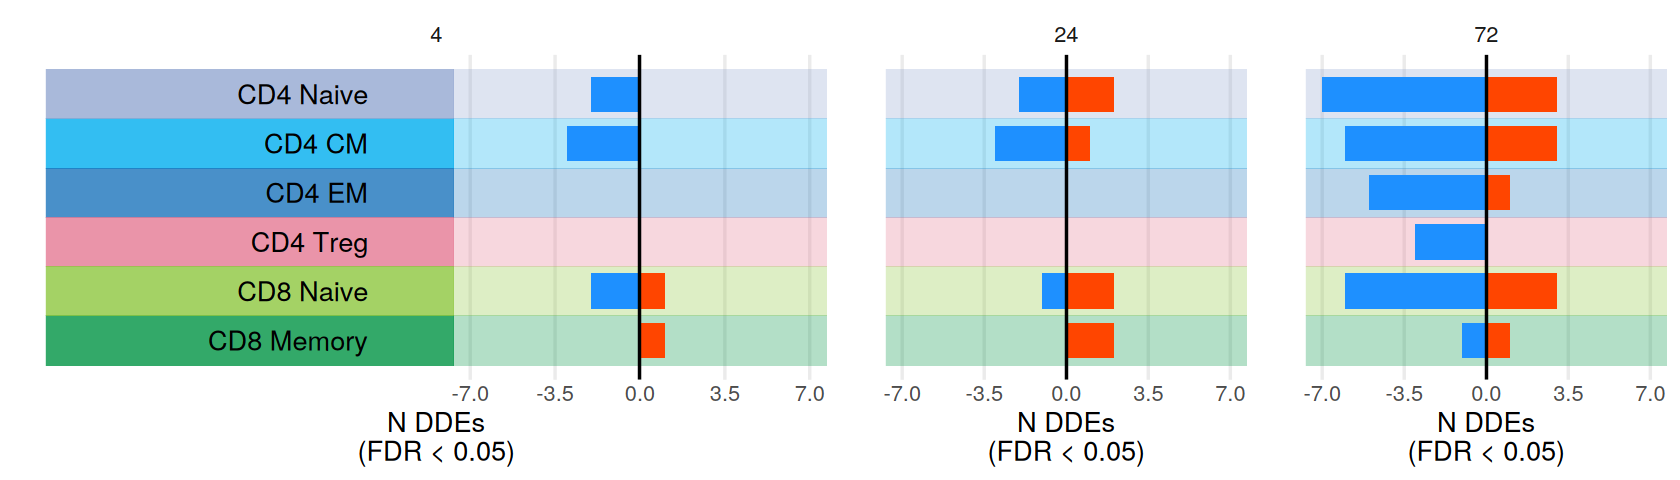

In [55]:
options(repr.plot.width = 14, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 3,
    rel_widths = c(2,1,1)
)
all_plots

In [56]:
dde_plot_file <- file.path(
    out_dir,
    paste0("lenalidomide_dde_barplot_",Sys.Date(),".pdf")
)
ggsave(dde_plot_file,
       all_plots,
       width = 14, height = 4)
out_files <- c(out_files, dde_plot_file)

## Hallmark pathway enrichment heatmaps

In [57]:
fdr_cutoff <- 0.05

In [58]:
hallmark_names <- read.csv("../common/gene_sets/hallmark_names.csv")

In [59]:
type_colors <- read.csv("../common/color_sets/aifi_cell_type_colors.csv")

Gradient colors

In [60]:
lo_gc <- data.frame(NES = seq(-3, -1.01, 0.01)) %>%
  mutate(nes_color = colorRampPalette(c("darkblue", "skyblue"))(n()))
mid_lo_gc <- data.frame(NES = seq(-1, 0, 0.01), nes_color = "gray80")
hi_gc <- data.frame(NES = seq(3,1.01,-0.01)) %>%
  mutate(nes_color = colorRampPalette(c("darkred", "coral"))(n()))
mid_hi_gc <- data.frame(NES = seq(1, 0.01, -0.01), nes_color = "gray80")

gc_df <- do.call(rbind, list(lo_gc, mid_lo_gc, mid_hi_gc, hi_gc))
gc_df$NES <- as.character(gc_df$NES)

In [61]:
all_hallmark <- read.csv(hallmark_file)

In [62]:
all_hallmark <- all_hallmark %>%
  filter(fg == "lenalidomide")

In [63]:
head(all_hallmark)

,fg,bg,timepoint,aifi_cell_type,pathway_label,NES,nomP,adjP,n_leadingEdge,n_pathway_genes,leadingEdge,pathway_genes
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>
1,lenalidomide,dmso,24,t_cd4_cm,Notch Signaling,1.517715,0.06371681,0.4571429,15,34,SAP30;TCF7L2;CUL1;RBX1;ARRB1,APH1A;ARRB1;CCND1;CUL1;DLL1;DLL1;DTX1;DTX2;DTX2;DTX4;FBXW11;FZD1;FZD5;FZD7;HES1;HEYL;JAG1;KAT2A;LFNG;MAML2;NOTCH1;NOTCH2;NOTCH3;PPARD;PRKCA;PSEN2;PSENEN;RBX1;SAP30;SKP1;ST3GAL6;TCF7L2;WNT2;WNT5A
2,lenalidomide,dmso,24,t_cd4_cm,Protein Secretion,1.509987,0.04588608,0.4571429,83,98,ATP1A1;SEC24D;DST;VPS4B;SEC31A;BET1;TPD52;ZW10;CLN5;ADAM10;LAMP2;TMX1;CD63;VAMP4;PAM;RAB5A;USO1;STX7;TMED2;ARFGAP3;LMAN1;RAB14;IGF2R;STX12;ARF1;TOM1L1;PPT1,ABCA1;ADAM10;ANP32E;AP1G1;AP2B1;AP2M1;AP2S1;AP3B1;AP3S1;ARCN1;ARF1;ARFGAP3;ARFGEF1;ARFGEF2;ARFIP1;ATP1A1;ATP6V1B1;ATP6V1H;ATP7A;BET1;BNIP3;CAV2;CD63;CLCN3;CLN5;CLTA;CLTC;COG2;COPB1;COPB2;COPE;CTSC;DNM1L;DOP1A;DST;EGFR;ERGIC3;GALC;GBF1;GLA;GNAS;GOLGA4;GOSR2;ICA1;IGF2R;KIF1B;KRT18;LAMP2;LMAN1;M6PR;MAPK1;MON2;NAPA;NAPG;OCRL;PAM;PPT1;RAB14;RAB22A;RAB2A;RAB5A;RAB9A;RER1;RPS6KA3;SCAMP1;SCAMP3;SCAMP3;SCRN1;SEC22B;SEC24D;SEC31A;SGMS1;SH3GL2;SNAP23;SNX2;SOD1;SSPN;STAM;STX12;STX16;STX7;TMED10;TMED2;TMX1;TOM1L1;TPD52;TSG101;TSPAN8;USO1;VAMP3;VAMP4;VAMP7;VPS45;VPS45;VPS4B;YIPF6;YKT6;ZW10
3,lenalidomide,dmso,24,t_cd4_cm,KRAS Signaling UP,1.459297,0.06666667,0.4571429,67,220,IKZF1;GALNT3;HBEGF;PRDM1;LAPTM5,ABCB1;ACE;ADAM17;ADAM8;ADAMDEC1;ADGRA2;ADGRL4;AKAP12;AKT2;ALDH1A2;ALDH1A3;AMMECR1;ANGPTL4;ANKH;ANO1;ANXA10;APOD;ARG1;ATG10;AVL9;BIRC3;BMP2;BPGM;BTBD3;BTC;C3AR1;CA2;CAB39L;CBL;CBR4;CBX8;CCL20;CCND2;CCSER2;CD37;CDADC1;CFB;CFB;CFB;CFB;CFB;CFB;CFB;CFH;CFHR2;CIDEA;CLEC4A;CMKLR1;CPE;CROT;CSF2;CSF2RA;CTSS;CXCL10;CXCR4;DCBLD2;DNMBP;DOCK2;DUSP6;EMP1;ENG;EPB41L3;EPHB2;EREG;ERO1A;ETS1;ETV1;ETV4;ETV5;EVI5;F13A1;F2RL1;FBXO4;FCER1G;FGF9;FLT4;FUCA1;G0S2;GABRA3;GADD45G;GALNT3;GFPT2;GLRX;GNG11;GPNMB;GPRC5B;GUCY1A1;GYPC;H2BC3;HBEGF;HDAC9;HKDC1;HOXD11;HSD11B1;ID2;IGF2;IGFBP3;IKZF1;IL10RA;IL1B;IL1RL2;IL2RG;IL33;IL7R;INHBA;IRF8;ITGA2;ITGB2;ITGBL1;JUP;KCNN4;KIF5C;KIF5C;KLF4;LAPTM5;LAT2;LCP1;LIF;LY96;MAFB;MALL;MAP3K1;MAP4K1;MAP4K1;MAP7;MMD;MMP10;MMP11;MMP11;MMP9;MPZL2;MTMR10;MTMR10;MYCN;NAP1L2;NGF;NIN;NR0B2;NR1H4;NRP1;PCP4;PCSK1N;PDCD1LG2;PECAM1;PEG3;PIGR;PLAT;PLAU;PLAUR;PLEK2;PLVAP;PPBP;PPP1R15A;PRDM1;PRELID3B;PRKG2;PRRX1;PSMB8;PSMB8;PSMB8;PSMB8;PSMB8;PSMB8;PSMB8;PSMB8;PTBP2;PTCD2;PTGS2;PTPRR;RABGAP1L;RBM4;RBP4;RELN;RETN;RGS16;SATB1;SCG3;SCG5;SCG5;SCG5;SCN1B;SDCCAG8;SDCCAG8;SEMA3B;SERPINA3;SLPI;SNAP25;SNAP91;SOX9;SPARCL1;SPON1;SPP1;SPRY2;ST6GAL1;STRN;TFPI;TLR8;TMEM100;TMEM158;TMEM176A;TMEM176B;TNFAIP3;TNFRSF1B;TNNT2;TOR1AIP2;TPH1;TRAF1;TRIB1;TRIB2;TSPAN1;TSPAN13;TSPAN7;USH1C;USP12;VWA5A;WDR33;WNT7A;YRDC;ZNF277;ZNF639
4,lenalidomide,dmso,24,t_cd4_cm,Spermatogenesis,1.452788,0.06429780,0.4571429,39,144,EZH2;CAMK4;TOPBP1;STRBP;CHFR,ACE;ACRBP;ACRV1;ACTL7B;ADAD1;ADAM2;ADAM2;ADCYAP1;AGFG1;AKAP4;ALOX15;ARL4A;ART3;AURKA;BRAF;BUB1;CAMK4;CCNA1;CCNB2;CCT6B;CDK1;CDKN3;CFTR;CHFR;CHRM4;CLGN;CLPB;CLVS1;CNIH2;COIL;CRISP2;CSNK2A2;CST8;DBF4;DCC;DDX25;DDX4;DMC1;DMRT1;DNAJB8;DPEP3;ELOVL3;EZH2;GAD1;GAPDHS;GFI1;GMCL1;GPR182;GRM8;GSG1;GSTM3;H1-6;HBZ;HOXB1;HSPA1L;HSPA1L;HSPA1L;HSPA1L;HSPA1L;HSPA2;HSPA4L;HTR5A;IDE;IFT88;IL12RB2;IL13RA2;IP6K1;JAM3;KIF2C;LDHC;LPIN1;MAP7;MAST2;MEP1B;MLF1;MLLT10;MTNR1A;MTOR;NAA11;NCAPH;NEFH;NEK2;NF2;NOS1;NPHP1;NPY5R;OAZ3;ODF1;PACRG;PAPOLB;PARP2;PCSK1N;PCSK4;PDHA2;PEBP1;PGK2;PGS1;PHF7;PHKG2;PIAS2;POMC;PRKAR2A;PRM2;PSMG1;RAD17;RAD17;RFC4;RPL39L;SCG3;SCG5;SCG5;SCG5;SEPTIN4;SHE;SIRT1;SLC12A2;SLC2A5;SNAP91;SPATA6;STAM2;STRBP;SYCP1;TALDO1;TCP11;TEKT2;THEG;TKTL1;TLE4;TNNI3;TNP1;TNP2;TOPBP1;TSN;TSSK2;TTK;TUBA3C;TULP2;VDAC3;YBX2;YBX2;ZC2HC1C;ZC3H14;ZNRF4;ZPBP
5,lenalidomide,dmso,24,t_cd4_cm,Unfolded Protein Response,1.390092,0.08763693,0.5244584,87,115,TSPYL2;PDIA5;ERN1;SEC31A;DNAJC3;XBP1;SRPRA;DNAJB9;SERP1;SLC30A5;EXOSC5;NFYA;SEC11A;HSP90B1;PDIA6;SRPRB;ATF6;DCP2;IMP3,ALDH18A1;ARFGAP1;ASNS;ATF3;ATF4;ATF6;ATP6V0D1;BAG3;BANF1;CALR;CCL2;CEBPB

Add treat_time, display labels for pathways, and cell type 

In [64]:
plot_hallmark <- all_hallmark %>%
  mutate(label_time = ifelse(timepoint == 4, "04", as.character(timepoint))) %>%
  mutate(treat_time = paste0(fg, "_", label_time)) %>%
  left_join(hallmark_names) %>%
  left_join(type_colors)

Joining with `by = join_by(pathway_label)`
Joining with `by = join_by(aifi_cell_type)`


In [65]:
top_n <- 20

sig_data <- plot_hallmark %>%
  filter(adjP < fdr_cutoff) %>%
  group_by(pathway) %>%
  arrange(adjP) %>%
  slice(1) %>%
  ungroup() %>%
  arrange(adjP) %>%
  head(top_n)

plot_data <- plot_hallmark %>%
  filter(pathway %in% sig_data$pathway)

xpos_df <- plot_data %>%
  select(cell_type_label, cell_type_xpos) %>%
  unique() %>%
  arrange(cell_type_xpos) %>%
  mutate(xpos = 1:n())

ypos_df <- plot_data %>%
  select(pathway_label) %>%
  unique() %>%
  arrange(pathway_label) %>%
  mutate(ypos = n():1)

timepoint_df <- data.frame(
    timepoint = c(4, 24, 72),
    timepoint_label = factor(c("Lenalidomide, 4 Hours", "Lenalidomide, 24 Hours", "Lenalidomide, 72 Hours"), 
                             levels = c("Lenalidomide, 4 Hours", "Lenalidomide, 24 Hours", "Lenalidomide, 72 Hours"))
)

plot_data <- plot_data %>%
  left_join(xpos_df) %>%
  left_join(ypos_df) %>%
  mutate(NES = as.character(round(NES, 2))) %>%
  left_join(gc_df) %>%
  left_join(timepoint_df)

Joining with `by = join_by(cell_type_label, cell_type_xpos)`
Joining with `by = join_by(pathway_label)`
Joining with `by = join_by(NES)`
Joining with `by = join_by(timepoint)`


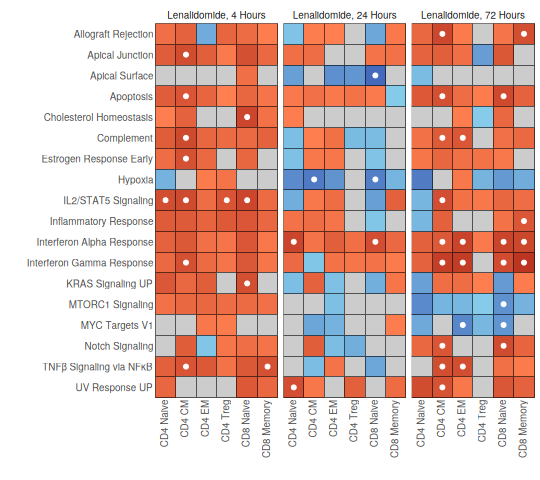

In [66]:
options(repr.plot.width = 4.5, repr.plot.height = 4)
hallmark_plot <- ggplot() +
  geom_tile(
      data = plot_data,
      aes(x = xpos,
          y = ypos,
          fill = nes_color),
      color = "black") +
  geom_point(
      data = plot_data %>% filter(adjP < fdr_cutoff),
      aes(x = xpos,
          y = ypos),
      color = "white",
      size = 0.9) +
  scale_fill_identity() +
  scale_x_continuous(
      "",
      breaks = xpos_df$xpos,
      labels = xpos_df$cell_type_label,
      expand = c(0, 0)) +
  scale_y_continuous(
      "",
      breaks = ypos_df$ypos,
      labels = ypos_df$pathway_label,
      expand = c(0, 0)) +
  facet_wrap(~ timepoint_label) +
  theme_bw(base_size = 7) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        panel.border = element_blank(),
        axis.ticks = element_blank(),
        strip.background = element_blank(),
        panel.grid = element_blank(),
        panel.background = element_rect(fill = "gray30"))
hallmark_plot

In [67]:
hallmark_plot_file <- file.path(
    out_dir,
    paste0("lenalidomide_hallmark_heatmap_",Sys.Date(),".pdf")
)
ggsave(hallmark_plot_file,
       hallmark_plot,
       width = 4.5, height = 4)
out_files <- c(out_files, hallmark_plot_file)

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TNFβ Signaling via NFκB' in 'mbcsToSbcs': for β (U+03B2)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'TNFβ Signaling via NFκB' in 'mbcsToSbcs': for κ (U+03BA)”


## Motif enrichment volcano plots

Select columns from DEG results to highlight TFs that are differentially expressed by color in the volcano plots

In [68]:
sel_deg <- all_deg %>%
  select(aifi_cell_type, timepoint, fg, bg, gene, adjP, logFC, direction) %>%
  rename(tf_gene = gene,
         tf_adjP = adjP,
         tf_logFC = logFC,
         tf_direction = direction) 

Read the motif enrichment results

In [69]:
all_dem <- read.csv(dem_file)

In [70]:
all_dem <- all_dem %>%
  mutate(timepoint = as.numeric(sub(".+_","",fg)),
         fg = sub("_.+","",fg),
         bg = sub("_.+","",bg)) %>%
  filter(fg == "lenalidomide") %>%
  left_join(sel_deg)

Joining with `by = join_by(aifi_cell_type, fg, bg, tf_gene, timepoint)`


Filter for expressed TFs, which will have tf_adjP, tf_logFC, and tf_direction joined from the DEG results

In [71]:
all_dem <- all_dem %>%
  filter(!is.na(tf_direction))

Convert Enrichment for motifs enriched near down-regulated genes to negative values

In [72]:
all_dem <- all_dem %>%
  mutate(Enrichment = ifelse(
      direction == "dn",
      -1 * Enrichment,
      Enrichment))

Add cell type labels and ordering

In [73]:
head(type_colors)

,aifi_cell_type,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos
,<chr>,<chr>,<chr>,<int>,<int>
1,t_cd4_naive,CD4 Naive,#93A7D1,1,7
2,t_cd4_cm,CD4 CM,#00AEEF,2,6
3,t_cd4_em,CD4 EM,#1C75BC,3,5
4,t_cd4_treg,CD4 Treg,#E57A93,4,4
5,t_cd8_naive,CD8 Naive,#8DC63F,5,3
6,t_cd8_memory,CD8 Memory,#009444,6,2


In [74]:
all_dem <- all_dem %>%
  left_join(type_colors) %>%
  mutate(cell_type_label = factor(cell_type_label, levels = type_colors$cell_type_label))

Joining with `by = join_by(aifi_cell_type)`


In [75]:
plot_dem <- all_dem %>%
  filter(timepoint == 24) %>%
  mutate(color = case_when(
      tf_adjP < 0.05 & tf_direction == "up" ~ "orangered",
      tf_adjP < 0.05 & tf_direction == "dn" ~ "dodgerblue",
      TRUE ~ "gray60",
  ))

In [76]:
dem_plot_data_file <- file.path(out_dir, paste0("lenalidomide_24hr_dem_data_", Sys.Date(), ".csv"))
write.csv(
    plot_dem,
    dem_plot_data_file,
    quote = FALSE,
    row.names = FALSE
)
out_files <- c(out_files, dem_plot_data_file)

In [77]:
max_enrich <- max(plot_dem$Enrichment)
max_mlp <- max(plot_dem$mlog10Padj)

In [78]:
label_top_n <- 8

up_label_dem <- plot_dem %>%
  filter(adjP < 0.05,
         direction == "up") %>%
  group_by(aifi_cell_type) %>%
  arrange(adjP) %>%
  filter(1:n() <= label_top_n | tf_gene == "IKZF1") %>%
  mutate(ypos = seq(max_mlp * 0.85, max_mlp * 0.15, length.out = n()),
         xpos = max_enrich * 1.1) %>%
  ungroup()

dn_label_dem <- plot_dem %>%
  filter(adjP < 0.05,
         direction == "dn") %>%
  group_by(aifi_cell_type) %>%
  arrange(adjP) %>%
  filter(1:n() <= label_top_n | tf_gene == "IKZF1") %>%
  mutate(ypos = seq(max_mlp * 0.85, max_mlp * 0.15, length.out = n()),
         xpos = -1 * max_enrich * 1.1) %>%
  ungroup()

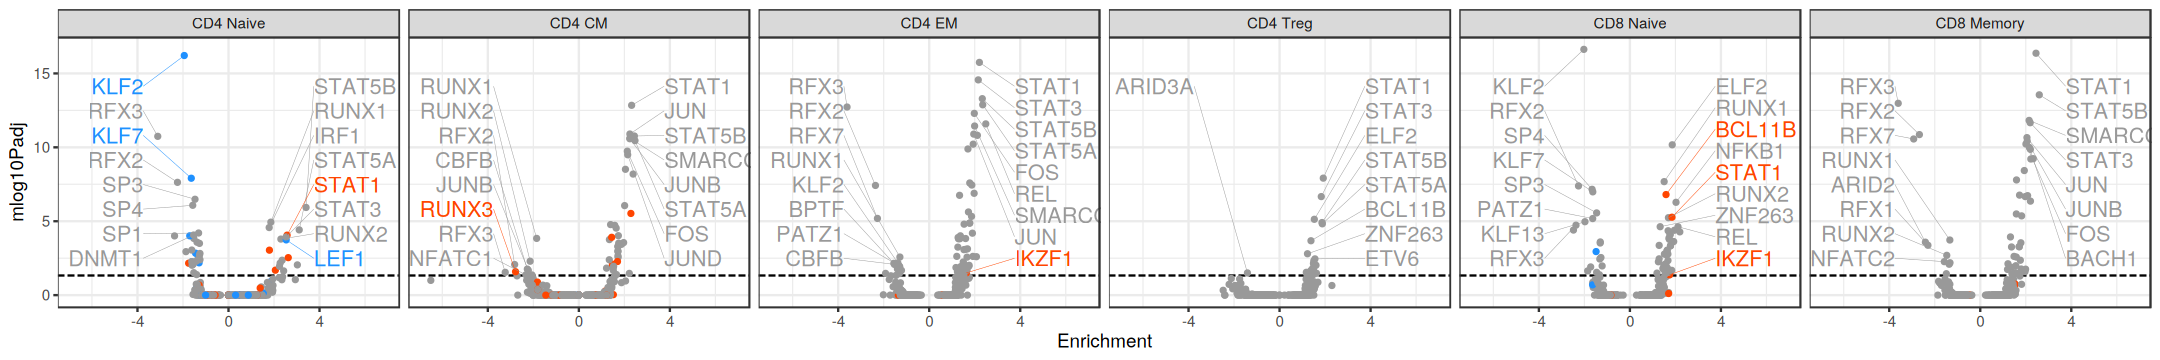

In [84]:
options(repr.plot.width = 18, repr.plot.height = 3)

volcano_plots <- ggplot() +
  geom_hline(
      yintercept = -log10(0.05),
      linetype = "longdash"
  ) +
  geom_point(
      data = plot_dem,
      aes(x = Enrichment,
          y = mlog10Padj,
          color = color),
      size = 1
  ) +
  geom_segment(
      data = up_label_dem,
      aes(x = xpos, xend = Enrichment,
          y = ypos, yend = mlog10Padj,
          color = color),
      linewidth = 0.1
  ) +
  geom_text(
      data = up_label_dem,
      aes(x = xpos,
          y = ypos,
          color = color,
          label = tf_gene),
      size = 4.5,
      hjust = 0
  ) +
  geom_segment(
      data = dn_label_dem,
      aes(x = xpos, xend = Enrichment,
          y = ypos, yend = mlog10Padj,
          color = color),
      linewidth = 0.1
  ) +
  geom_text(
      data = dn_label_dem,
      aes(x = xpos,
          y = ypos,
          color = color,
          label = tf_gene),
      size = 4.5,
      hjust = 1
  ) +
  scale_color_identity() +
  scale_x_continuous(
      limits = c(-2 * max_enrich, 2 * max_enrich)
  ) +
  facet_wrap(
      ~ cell_type_label,
      ncol = 6,
      nrow = 1
  ) +
  theme_bw()

volcano_plots

In [85]:
dem_plot_file <- file.path(
    out_dir,
    paste0("lenalidomide_24hr_dem_volcano_plots_",Sys.Date(),".pdf")
)
ggsave(dem_plot_file,
       volcano_plots,
       width = 18, height = 3)
out_files <- c(out_files, dem_plot_file)

# Store results in HISE

Finally, we store the output file in our Collaboration Space for later retrieval and use. We need to provide the UUID for our Collaboration Space (aka `studySpaceId`), as well as a title for this step in our analysis process.

The hise function `uploadFiles()` also requires the FileIDs from the original fileset for reference.

In [81]:
study_space_uuid <- "40df6403-29f0-4b45-ab7d-f46d420c422e"
title <- paste("VRd TEA-seq Fig 2 (Lenalidomide)", Sys.Date())

In [82]:
out_list <- as.list(out_files)

In [83]:
out_list

[[1]]
[1] "output/figure_4/lenalidomide_deg_summary_data_2026-10-02.csv"

[[2]]
[1] "output/figure_4/lenalidomide_deg_barplot_2026-10-02.pdf"

[[3]]
[1] "output/figure_4/lenalidomide_dap_summary_data_2026-10-02.csv"

[[4]]
[1] "output/figure_4/lenalidomide_dap_barplot_2026-10-02.pdf"

[[5]]
[1] "output/figure_4/lenalidomide_dde_summary_data_2026-10-02.csv"

[[6]]
[1] "output/figure_4/lenalidomide_dde_barplot_2026-10-02.pdf"

[[7]]
[1] "output/figure_4/lenalidomide_hallmark_heatmap_2026-10-02.pdf"

[[8]]
[1] "output/figure_4/lenalidomide_24hr_dem_data_2026-10-02.csv"

[[9]]
[1] "output/figure_4/lenalidomide_24hr_dem_volcano_plots_2026-10-02.pdf"

In [84]:
in_list <- c(deg_uuid, dep_uuid, dap_uuid, hallmark_uuid, dem_uuid)

In [85]:
in_list

[[1]]
[1] "8a6de5d9-4939-45cc-b77e-f2d8237a68b7"

[[2]]
[1] "4cbaa9ab-f8ef-495d-ac5e-1f1d99d33e33"

[[3]]
[1] "a8973524-cc71-40d5-8edf-3d6a9e0a77d4"

[[4]]
[1] "4f05f2a0-59d2-4d04-b948-70d541613e71"

[[5]]
[1] "42adb44f-71d2-4d8b-a80c-73b0833d6a1d"

In [86]:
sessionInfo()

R version 4.4.1 (2024-06-14)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/workspace/environment/archrpixiv12/.pixi/envs/default/lib/libopenblasp-r0.3.33.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8    LC_NUMERIC=C        LC_TIME=C          
 [4] LC_COLLATE=C        LC_MONETARY=C       LC_MESSAGES=C      
 [7] LC_PAPER=C          LC_NAME=C           LC_ADDRESS=C       
[10] LC_TELEPHONE=C      LC_MEASUREMENT=C    LC_IDENTIFICATION=C

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] cowplot_1.2.0 ggrepel_0.9.8 ggplot2_4.0.3 dplyr_1.2.1   purrr_1.2.2  
[6] hise_3.6.15  

loaded via a namespace (and not attached):
 [1] gtable_0.3.6       jsonlite_2.0.0     compiler_4.4.1     crayon_1.5.3      
 [5] tidyselect_1.2.1   Rcpp_1.1.1-1.1     IRdisplay_1.1      bitops_1.0-9      

In [87]:
uploadFiles(
    files = out_list,
    studySpaceId = study_space_uuid,
    title = title,
    inputFileIds = in_list,
    store = "project",
    doPrompt = FALSE
)

[2026-10-02 13:14:20] INFO  Calling uploadFiles
[2026-10-02 13:14:36] INFO  Finished uploadFiles successfully (time_elapsed=13.694s)


$Message
[1] "General Okay-ness"

$VisualizationId
[1] "00000000-0000-0000-0000-000000000000"

$AbstractionId
[1] "00000000-0000-0000-0000-000000000000"

$TraceId
[1] "4ba33646-5e98-4496-96f5-5c01df412a22"

$ProcessId
[1] "5b02343f-7fbe-49f1-b9e5-76c0a9f92620"

$WorkflowId
[1] "5e782d4e-76f3-4e05-8ea9-894e5684cf0b"

$FileIds
$FileIds[[1]]
[1] "31facb8d-4153-48ae-bc91-8d294b931580"

$FileIds[[2]]
[1] "6898878c-4cf1-4796-ae5a-96b7c6020caa"

$FileIds[[3]]
[1] "044d28bd-851e-4326-b274-589b0296d105"

$FileIds[[4]]
[1] "02d272cc-0328-4c8e-8e9c-f04c4b671e1b"

$FileIds[[5]]
[1] "84285efe-2e56-46cf-ae31-0dc961c7828d"

$FileIds[[6]]
[1] "43117e15-bc79-484e-9e0d-8110b16e73e9"

$FileIds[[7]]
[1] "985edd5f-9a4a-4a30-b60b-e8e372a91148"

$FileIds[[8]]
[1] "a208ae9a-ecb5-4a29-8523-49c65333980f"

$FileIds[[9]]
[1] "58f78e21-239d-41bf-887d-7748e3eb2b17"